## Обучение моделей 2го задания

### Импорты

In [1]:
import os
from collections import Counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

import solution_utils as su

TRAIN_PATH = os.environ.get("HW2_TRAIN", "hw1_train.jsonl")
FRAME_CACHE = "frame_all.pkl"
SEED = 42
N_JOBS = -1
os.makedirs("results", exist_ok=True)

### Данные и чистка

In [2]:
if os.path.exists(FRAME_CACHE):
    frame_all = pd.read_pickle(FRAME_CACHE)
else:
    frame_all = su.to_frame(su.read_dialogs(TRAIN_PATH))
    frame_all.to_pickle(FRAME_CACHE)

print("диалогов:", len(frame_all), " размечено по реакции:", frame_all.reaction.notna().sum())
df = frame_all[frame_all.reaction.notna()].reset_index(drop=True)
unlabeled = frame_all[frame_all.reaction.isna()].reset_index(drop=True)  # диалоги без меток: пригодятся для признаков
print("с меткой:", len(df), " без метки:", len(unlabeled))

диалогов: 10000  размечено по реакции: 3000
с меткой: 3000  без метки: 7000


### Разбиение и кросс-валидация

In [3]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(df, df.reaction, df.group))
train, test = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
print("train:", len(train), train.reaction.value_counts(normalize=True).round(3).to_dict())
print("test: ", len(test), test.reaction.value_counts(normalize=True).round(3).to_dict())
print("общих групп:", len(set(train.group) & set(test.group)))
assert not set(train.dialog_id) & set(unlabeled.dialog_id)

outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
inner_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + 2)
outer_folds = list(outer_cv.split(train, train.reaction, train.group))

METRIC_TABLE_COLS = [
    "model", "macro_f1", "macro_f1_bal", "accuracy",
    "balanced_acc", "R_negative", "R_neutral", "R_positive", "F1_positive"
]


def nested_cv(name, models):
    """Оценка модели вместе с процедурой подбора параметров на кросс-валидации"""
    pipe, grid = models[name]
    oof = np.empty(len(train), dtype=object); chosen = []
    for fit_idx, val_idx in outer_folds:
        fit_part, val_part = train.iloc[fit_idx], train.iloc[val_idx]
        if grid:
            search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="f1_macro", n_jobs=N_JOBS)
            search.fit(fit_part, fit_part.reaction, groups=fit_part.group)
            model, best = search.best_estimator_, search.best_params_
        else:
            model, best = clone(pipe).fit(fit_part, fit_part.reaction), {}
        oof[val_idx] = model.predict(val_part); chosen.append(best)
    return oof, chosen


def cv_fixed(make_model):
    """Быстрая оценка с фиксированными параметрами на кросс-валидации"""
    oof = np.empty(len(train), dtype=object)
    for fit_idx, val_idx in outer_folds:
        model = make_model().fit(train.iloc[fit_idx], train.reaction.iloc[fit_idx])
        oof[val_idx] = model.predict(train.iloc[val_idx])
    return oof


def metrics_table(oof_by_name):
    """сводная таблица метрик по всем моделям"""
    rows = [{"model": n, **su.reaction_metrics(train.reaction, p)} for n, p in oof_by_name.items()]
    return pd.DataFrame(rows)[METRIC_TABLE_COLS].round(3)


def fold_f1(oof):
    """разброс macro-F1 по блокам"""
    return np.array([su.reaction_metrics(train.reaction.iloc[v], oof[v])["macro_f1"] for _, v in outer_folds])


def modal(params_list):
    """самые частые параметры из вложенной кросс-валидации.
    Необходим для стеккинга"""
    return dict(Counter(tuple(sorted(p.items())) for p in params_list).most_common(1)[0][0])


def fit_final(models):
    """итоговое обучение на всём train"""
    return {n: (GridSearchCV(p, g, cv=inner_cv, scoring="f1_macro", n_jobs=N_JOBS)
                .fit(train, train.reaction, groups=train.group).best_estimator_
                if g else clone(p).fit(train, train.reaction))
            for n, (p, g) in models.items()}

train: 2400 {'neutral': 0.591, 'negative': 0.308, 'positive': 0.101}
test:  600 {'neutral': 0.592, 'negative': 0.308, 'positive': 0.1}
общих групп: 0


### Загрузка старых моделей

In [4]:
reaction_models = su.init_reaction_models()
OLD = {n.removeprefix("hw1_"): m for n, m in reaction_models.items() if n.startswith("hw1_")}
print("загружены модели hw1:", list(OLD))

old_oof = {n: cv_fixed(lambda m=m: clone(m)) for n, m in OLD.items()}
old_cv = metrics_table({f"hw1_{n}": p for n, p in old_oof.items()})
old_cv.to_csv("results/cv_old.csv", index=False)
su.show_table(old_cv)

c:\Users\hp\OneDrive\Рабочий стол\rep_hw\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DummyClassifier from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\hp\OneDrive\Рабочий стол\rep_hw\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\hp\OneDrive\Рабочий стол\rep_hw\venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 

загружены модели hw1: ['dummy_most_frequent', 'linear_svm', 'linear_svm_my', 'logreg', 'logreg_my', 'nb', 'nb_my']


,model,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
0,hw1_dummy_most_frequent,0.248,0.167,0.591,0.333,0.000,1.000,0.000,0.000
1,hw1_linear_svm,0.577,0.528,0.693,0.549,0.527,0.852,0.267,0.378
2,hw1_linear_svm_my,0.614,0.559,0.725,0.578,0.551,0.890,0.292,0.423
3,hw1_logreg,0.579,0.534,0.689,0.552,0.541,0.837,0.280,0.386
4,hw1_logreg_my,0.634,0.599,0.726,0.611,0.629,0.839,0.366,0.458
5,hw1_nb,0.479,0.415,0.660,0.479,0.556,0.817,0.066,0.120
6,hw1_nb_my,0.585,0.537,0.691,0.558,0.604,0.810,0.259,0.385


In [5]:
best_old = old_cv.sort_values("macro_f1").iloc[-1]["model"]
print("лучшая старая модель на кросс-валидации:", best_old, old_cv.set_index("model").loc[best_old, "macro_f1"])

лучшая старая модель на кросс-валидации: hw1_logreg_my 0.634


### Признаки для новых моделей

Модели HW1 работали на разреженном TF-IDF: десятки тысяч столбцов, и линейная модель умеет складывать вклады многих слов.
Дереву такой вход не подходит: каждое слово встречается в нескольких диалогах, оно делит выборку по одному слову за шаг
и быстро упирается в малое число объектов в листе, а случайный лес на каждом разбиении видит лишь случайную часть столбцов.
Деревьям нужны плотные и компактные признаки, в которых уже собрана информация. У нас их два вида:

- **LSA на TF-IDF**: несколько десятков «тем» вместо десятков тысяч слов (по трём текстам: остальные реплики
  пользователя, начало последнего ответа модели, первый запрос);
- **Ручные признаки реакции**: 
    1. Размеры диалога (все длины сглажены логарифмом ln(1 + x)):
       - число реплик пользователя и число ответов ассистента;
       - длина первой реплики пользователя;
       - длина последней реплики пользователя;
       - средняя длина остальных реплик пользователя (всех, кроме последней);
       - суммарная длина ответов ассистента;
       - длина первого ответа ассистента и длина последнего ответа ассистента;
       - отношение длины последней реплики пользователя к длине первой (не больше 10).

    2. Пунктуация:
       - число восклицательных и число вопросительных знаков в последней реплике пользователя;
       - число восклицательных и число вопросительных знаков в остальных его репликах;
       - заканчивается ли последняя реплика пользователя вопросительным знаком (0 или 1).

    3. Повторение запроса — сходство Жаккара, то есть доля общих слов среди всех
       уникальных слов двух текстов (от 0 до 1):
       - между последней и предыдущей репликами пользователя;
       - между последней и первой репликами пользователя.

    4. Тематические словари — сколько раз найдены слова (не больше 5), отдельно
       в последней реплике пользователя и отдельно в остальных его репликах:
       - благодарность;
       - недовольство и сообщения об ошибке;
       - вежливая просьба;
       - просьба продолжить;
       - согласие, подтверждение понимания.
       Регистр не учитывается, русские слова ищутся по основам.

    5. Служебные метки, которыми при чистке текста заменены блоки кода, формулы и ссылки:
       - встречается ли метка в последней реплике пользователя (0 или 1) —
         отдельно для кода, для формул, для ссылок;
       - сколько таких меток в остальных репликах пользователя —
         отдельно для кода, для формул, для ссылок.

    6. Состав символов последней реплики пользователя:
       - доля кириллических букв среди всех букв;
       - доля заглавных букв среди всех букв;
       - доля цифр среди всех символов;
       - число слов, сглаженное логарифмом ln(1 + x).

In [6]:
FEATURIZER = su.tree_features

### Случайный лес и два вида градентного бустинга

Все новые модели получают одни и те же плотные признаки (`FEATURIZER`), параметры подбираются на внутренней кросс-валидации, оценка тоже на кросс-валидации

- `rf_tfidf` — случайный лес на сыром TF-IDF
- `rf_lsa` — случайный лес на LSA и ручных признаках;
- `hgb_lsa` — `HistGradientBoostingClassifier` гистограмный бустинг scikit-learn
- `gb_lsa` — `GradientBoostingClassifier` классический бустинг scikit-learn
- `dt_lsa` — одно дерево решений: показывает, сколько преимуществ даёт ансамбль (в итоговый набор не входит).


In [7]:
NEW = su.hw2_reaction_models(featurizer=FEATURIZER)
WEAK = {"dt_lsa": (Pipeline(
    [("f", FEATURIZER()),
    ("m", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))]),
    {"m__max_depth": [3, 5, 8], "m__min_samples_leaf": [5, 20]})}

new_oof, new_params = {}, {}
for name in {**NEW, **WEAK}:
    new_oof[name], new_params[name] = nested_cv(name, {**NEW, **WEAK})

new_cv = metrics_table({f"hw2_{n}": p for n, p in new_oof.items()})
new_cv.to_csv("results/cv_new_single.csv", index=False)
su.show_table(new_cv)

,model,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
0,hw2_rf_tfidf,0.630,0.580,0.728,0.593,0.539,0.891,0.350,0.476
1,hw2_rf_lsa,0.639,0.608,0.721,0.613,0.551,0.859,0.428,0.509
2,hw2_hgb_lsa,0.614,0.621,0.688,0.623,0.581,0.773,0.514,0.470
3,hw2_gb_lsa,0.606,0.549,0.723,0.570,0.511,0.907,0.292,0.418
4,hw2_dt_lsa,0.522,0.569,0.591,0.572,0.425,0.672,0.617,0.335


In [ ]:
path = []  # путь к лучшей модели: что пробовали и что получили

def record(step, idea, oof, note=""):
    """Записывает результаты эксперимента в общую историю"""
    scores = fold_f1(oof)
    row = {"этап": step, "что проверяем": idea, **{k: v for k, v in su.reaction_metrics(train.reaction, oof).items()
           if k in ("macro_f1", "balanced_acc", "accuracy")},
           "macro_f1 по блокам": f"{scores.mean():.3f} ± {scores.std():.3f}", "комментарий": note}
    path.append(row)
    return row["macro_f1"]

### Стекинг
Код ниже проверяет две гипотезы:
Что будет, если объединить только старые модели из HW1?
Что будет, если к старым моделям добавить новые деревья из HW2?

In [10]:
def tuned(models, name, params_list):
    return clone(models[name][0]).set_params(**modal(params_list))


def make_stack(old_pick, new_pick, new_estimators):
    """
    Создает и настраивает модель стекинга (StackingClassifier).
    Объединяет выбранные базовые модели из HW1 (линейные) и HW2 (деревья/ансамбли),
    используя логистическую регрессию в качестве метамодели. 
    Для генерации OOF-предсказаний (out-of-fold) используется кросс-валидация
    с группировкой (GroupedFolds), чтобы исключить утечку данных между train и test"""
    estimators = [(f"hw1_{n}", clone(OLD[n])) for n in old_pick] + [(f"hw2_{n}", clone(new_estimators[n])) for n in new_pick]
    return StackingClassifier(
        estimators, final_estimator=LogisticRegression(class_weight="balanced", max_iter=2000),
        stack_method="auto",
        cv=su.GroupedFolds(n_splits=5, shuffle=True, random_state=SEED))


OLD_PICK = ["logreg_my", "nb_my", "linear_svm_my"]
STACKS = {
    "stack_old_lr": (OLD_PICK, []),
    "stack_all_lr": (OLD_PICK, ["rf_lsa", "hgb_lsa"]),
}
new_cv_estimators = {n: tuned(NEW, n, new_params[n]) for n in NEW}   # параметры из вложенной кросс-валидации
stack_oof = {}
for name, (old_pick, new_pick) in STACKS.items():
    stack_oof[name] = cv_fixed(lambda: make_stack(old_pick, new_pick, new_cv_estimators))
    record("5", f"{name}: базовые {old_pick + new_pick}, метамодель logreg", stack_oof[name])

stack_cv = metrics_table({f"hw2_{n}": p for n, p in stack_oof.items()})
stack_cv.to_csv("results/cv_new_stack.csv", index=False)
su.show_table(stack_cv)

,model,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
0,hw2_stack_old_lr,0.598,0.639,0.666,0.639,0.619,0.702,0.597,0.411
1,hw2_stack_all_lr,0.626,0.672,0.683,0.672,0.621,0.717,0.679,0.484


### Все модели кросс-валидации

In [11]:
cv_all = pd.concat([old_cv, new_cv[new_cv.model != "hw2_dt_lsa"], stack_cv], ignore_index=True)
cv_all.to_csv("results/cv_all.csv", index=False)
display(su.show_table(cv_all))

best_new = cv_all[cv_all.model.str.startswith("hw2_")].sort_values("macro_f1").iloc[-1]["model"]
f1_new = cv_all.set_index("model").loc[best_new, "macro_f1"]
f1_old = cv_all.set_index("model").loc[best_old, "macro_f1"]
print(f"лучшая новая: {best_new} ({f1_new:.3f}), лучшая старая: {best_old} ({f1_old:.3f}), разность: {f1_new - f1_old:+.3f}")

,model,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
0,hw1_dummy_most_frequent,0.248,0.167,0.591,0.333,0.000,1.000,0.000,0.000
1,hw1_linear_svm,0.577,0.528,0.693,0.549,0.527,0.852,0.267,0.378
2,hw1_linear_svm_my,0.614,0.559,0.725,0.578,0.551,0.890,0.292,0.423
3,hw1_logreg,0.579,0.534,0.689,0.552,0.541,0.837,0.280,0.386
4,hw1_logreg_my,0.634,0.599,0.726,0.611,0.629,0.839,0.366,0.458
5,hw1_nb,0.479,0.415,0.660,0.479,0.556,0.817,0.066,0.120
6,hw1_nb_my,0.585,0.537,0.691,0.558,0.604,0.810,0.259,0.385
7,hw2_rf_tfidf,0.630,0.580,0.728,0.593,0.539,0.891,0.350,0.476
8,hw2_rf_lsa,0.639,0.608,0.721,0.613,0.551,0.859,0.428,0.509
9,hw2_hgb_lsa,0.614,0.621,0.688,0.623,0.581,0.773,0.514,0.470


лучшая новая: hw2_rf_lsa (0.639), лучшая старая: hw1_logreg_my (0.634), разность: +0.005


### Итоговое обучение и тест

In [12]:
fitted = {f"hw1_{n}": m for n, m in OLD.items()}
fitted.update({f"hw2_{n}": m for n, m in fit_final(NEW).items()})
final_estimators = {n: fitted[f"hw2_{n}"] for n in NEW}
for name, (old_pick, new_pick) in STACKS.items():
    fitted[f"hw2_{name}"] = make_stack(old_pick, new_pick, final_estimators).fit(train, train.reaction)

test_pred = {n: m.predict(test) for n, m in fitted.items()}
test_table = pd.DataFrame(
    [{"model": n, **su.reaction_metrics(test.reaction, p)} for n, p in test_pred.items()])[METRIC_TABLE_COLS].round(3)
test_table.to_csv("results/test_all.csv", index=False)
su.show_table(test_table)

,model,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
0,hw1_dummy_most_frequent,0.248,0.167,0.592,0.333,0.000,1.000,0.000,0.000
1,hw1_linear_svm,0.597,0.549,0.697,0.562,0.514,0.856,0.317,0.442
2,hw1_linear_svm_my,0.629,0.584,0.718,0.594,0.551,0.865,0.367,0.489
3,hw1_logreg,0.605,0.564,0.695,0.573,0.530,0.839,0.350,0.467
4,hw1_logreg_my,0.637,0.605,0.715,0.612,0.616,0.820,0.400,0.500
5,hw1_nb,0.470,0.407,0.647,0.470,0.546,0.797,0.067,0.121
6,hw1_nb_my,0.609,0.562,0.703,0.579,0.627,0.811,0.300,0.434
7,hw2_rf_tfidf,0.632,0.580,0.728,0.593,0.535,0.893,0.350,0.483
8,hw2_rf_lsa,0.629,0.597,0.718,0.604,0.557,0.856,0.400,0.475
9,hw2_hgb_lsa,0.615,0.654,0.670,0.653,0.627,0.699,0.633,0.481


### Сравнение результатов на кросс-валидации и тесте

In [13]:
summary = (cv_all[["model", "macro_f1", "balanced_acc", "accuracy"]]
           .merge(test_table[["model", "macro_f1", "balanced_acc", "accuracy"]], on="model", suffixes=(" (CV)", " (test)")))
summary.to_csv("results/summary.csv", index=False)
su.show_table(summary)

,model,macro_f1 (CV),balanced_acc (CV),accuracy (CV),macro_f1 (test),balanced_acc (test),accuracy (test)
0,hw1_dummy_most_frequent,0.248,0.333,0.591,0.248,0.333,0.592
1,hw1_linear_svm,0.577,0.549,0.693,0.597,0.562,0.697
2,hw1_linear_svm_my,0.614,0.578,0.725,0.629,0.594,0.718
3,hw1_logreg,0.579,0.552,0.689,0.605,0.573,0.695
4,hw1_logreg_my,0.634,0.611,0.726,0.637,0.612,0.715
5,hw1_nb,0.479,0.479,0.660,0.470,0.470,0.647
6,hw1_nb_my,0.585,0.558,0.691,0.609,0.579,0.703
7,hw2_rf_tfidf,0.630,0.593,0.728,0.632,0.593,0.728
8,hw2_rf_lsa,0.639,0.613,0.721,0.629,0.604,0.718
9,hw2_hgb_lsa,0.614,0.623,0.688,0.615,0.653,0.670


### Лучшая новая и лучшая старая: матрицы ошибок рядом

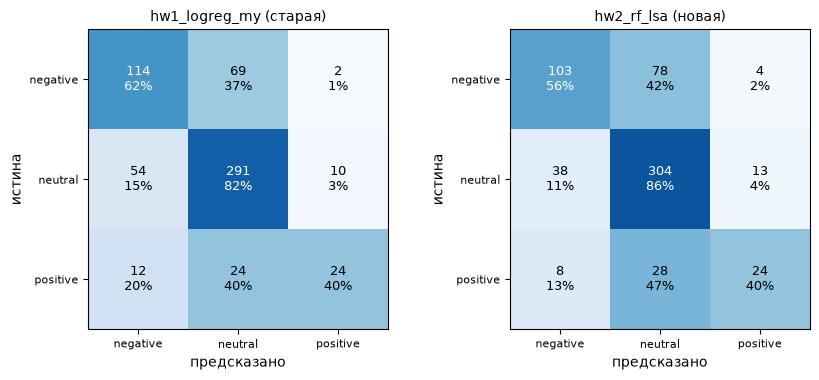

In [14]:
su.plot_confusions(
    test.reaction,
    {f"{best_old} (старая)": test_pred[best_old], f"{best_new} (новая)": test_pred[best_new]},
    ncols=2
)

### Где новая модель исправила ошибку старой, а где ошиблась там, где старая была права

In [15]:
y, p_old, p_new = test.reaction.to_numpy(), np.asarray(test_pred[best_old]), np.asarray(test_pred[best_new])
fixed = test[(p_old != y) & (p_new == y)].assign(old=p_old[(p_old != y) & (p_new == y)])
broken = test[(p_old == y) & (p_new != y)].assign(new=p_new[(p_old == y) & (p_new != y)])
both_wrong = ((p_old != y) & (p_new != y)).sum()
print(f"новая исправила: {len(fixed)}, новая сломала: {len(broken)}, обе ошиблись: {both_wrong}, обе правы: {((p_old == y) & (p_new == y)).sum()}")

def show(frame, extra, n=8):
    for _, r in frame.head(n).iterrows():
        text = r.last_raw.replace("\n", " ")
        print(f"[истина: {r.reaction} | {extra}: {r[extra]} | реплик: {r.n_user}] {text[:220]}")

print("\n=== новая права, старая нет ==="); show(fixed, "old")
print("\n=== старая права, новая нет ==="); show(broken, "new")

новая исправила: 35, новая сломала: 33, обе ошиблись: 136, обе правы: 396

=== новая права, старая нет ===
[истина: neutral | old: negative | реплик: 8] What formula do i use the data in a column and a cell to calculate the values ?
[истина: neutral | old: negative | реплик: 5] after cg/bg there are 5 options. what would most likely be those according to your knowledge? (this column has headline which they all fall unto, there is in total 7 ''things'' under same headline)
[истина: neutral | old: negative | реплик: 6] in servicenow i need to show a field message when the user is selecting the start date on the change request. i need to show a field msg and This is not happens when creating a new change request , this will happens only
[истина: neutral | old: negative | реплик: 7] task 4 To enter the poetry club via the back door, you need to be extra polite. So to derive the password, this time you need to correctly capitalize the word and add ', please' at the end. Implement the functi

### Важность признаков

Для случайного леса и классического бустинга считаем среднее **уменьшение неоднородности (MDI)** и **перестановочную важность** (падение macro-F1 при перемешивании признака на отложенных данных: одном внешнем блоке кросс-валидации, который модель не видела).
Тест здесь не используется.

In [16]:
def importance_report(name):
    fit_idx, val_idx = outer_folds[0]
    pipe = clone(fitted[f"hw2_{name}"]).fit(train.iloc[fit_idx], train.reaction.iloc[fit_idx])
    feats, model = pipe.named_steps["f"], pipe.named_steps["m"]
    X_val = feats.transform(train.iloc[val_idx])
    X_val = X_val.toarray() if hasattr(X_val, "toarray") else X_val
    perm = permutation_importance(model, X_val, train.reaction.iloc[val_idx], scoring="f1_macro",
                                  n_repeats=20, random_state=SEED, n_jobs=-1)
    imp = pd.DataFrame({"feature": feats.get_feature_names_out(), "MDI": model.feature_importances_,
                        "permutation": perm.importances_mean, "perm_std": perm.importances_std})
    imp["block"] = imp.feature.str.split("__").str[0]
    return imp


importances = {name: importance_report(name) for name in ("rf_lsa", "gb_lsa")}
for name, imp in importances.items():
    imp.to_csv(f"results/importance_{name}.csv", index=False)
    rho = spearmanr(imp.MDI, imp.permutation).statistic
    print(f"{name}: ранговая корреляция MDI и перестановочной важности = {rho:.2f}")

rf_lsa: ранговая корреляция MDI и перестановочной важности = -0.08
gb_lsa: ранговая корреляция MDI и перестановочной важности = 0.45


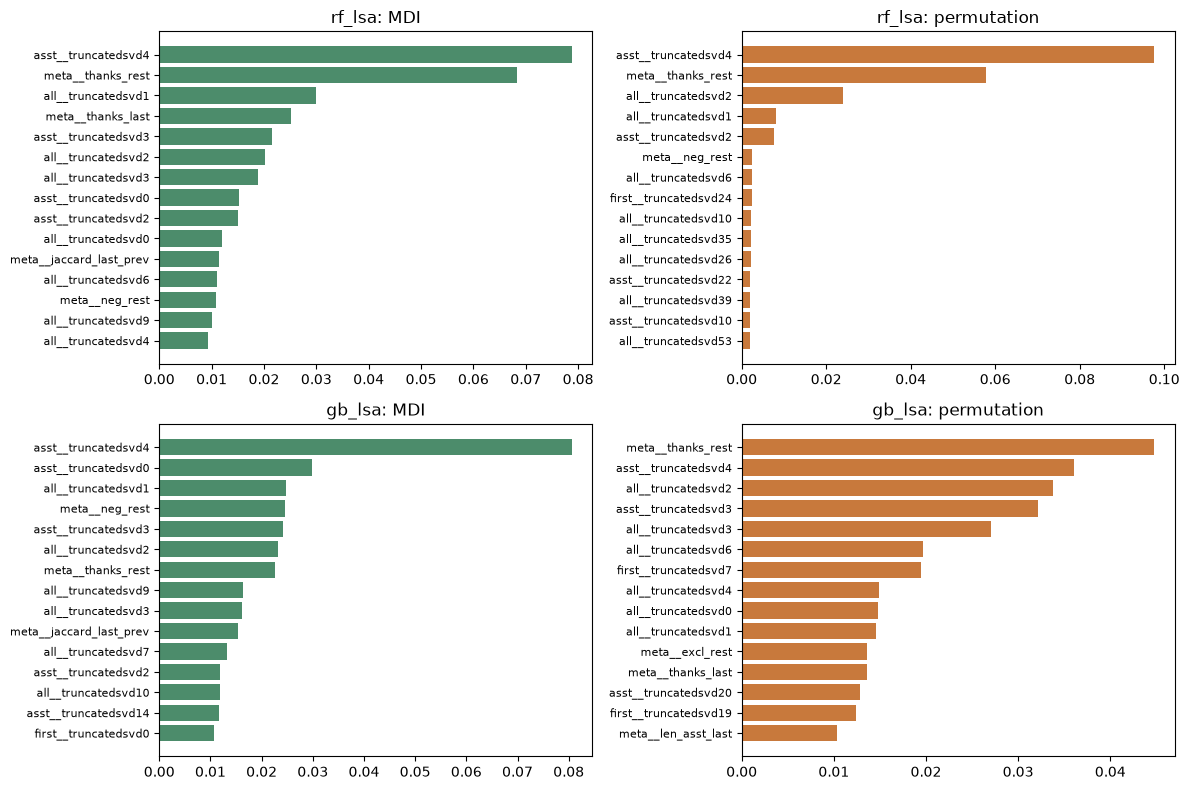

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, imp) in zip(axes, importances.items()):
    for ax, col in zip(row, ("MDI", "permutation")):
        top = imp.sort_values(col).tail(15)
        ax.barh(top.feature, top[col], color="#4c8c6b" if col == "MDI" else "#c8793c")
        ax.set_title(f"{name}: {col}"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

Как читать: MDI считается на обучающих данных и завышает важность признаков с большим числом разных значений (непрерывные: компоненты LSA, длины),
а при коррелированных признаках делит важность между ними. Перестановочная важность меряет вклад признака в качество на невиденных данных; она показывает
и признаки, которые лес использует, но которые не помогают (значение около нуля или отрицательное). Если порядок признаков по двум мерам различается —
это ожидаемо, и разбор расхождения (какие признаки и почему)

### Сохранение новых моделей

In [25]:
OUT = "artifacts/reaction_models"
os.makedirs(OUT, exist_ok=True)

for name, model in fitted.items():
    if name.startswith("hw2_"):
        path_ = os.path.join(OUT, f"reaction_{name}.joblib")
        joblib.dump(model, path_, compress=3)
        print(f"saved: {path_}  {os.path.getsize(path_) / 1e6:.1f} МБ")

saved: artifacts/reaction_models/reaction_hw2_rf_tfidf.joblib  3.7 МБ
saved: artifacts/reaction_models/reaction_hw2_rf_lsa.joblib  21.9 МБ
saved: artifacts/reaction_models/reaction_hw2_hgb_lsa.joblib  20.6 МБ
saved: artifacts/reaction_models/reaction_hw2_gb_lsa.joblib  20.5 МБ
saved: artifacts/reaction_models/reaction_hw2_stack_old_lr.joblib  5.0 МБ
saved: artifacts/reaction_models/reaction_hw2_stack_all_lr.joblib  27.3 МБ
